Цель: выделить группы пациентов с разным уровнем риска (например, "низкий", "средний", "высокий").

Польза: врачи смогут назначать разные стратегии профилактики и лечения.

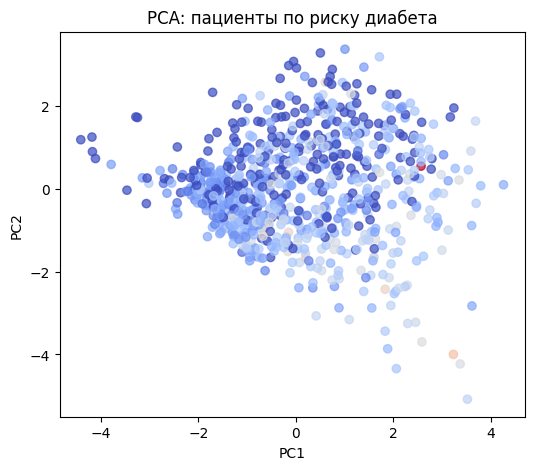

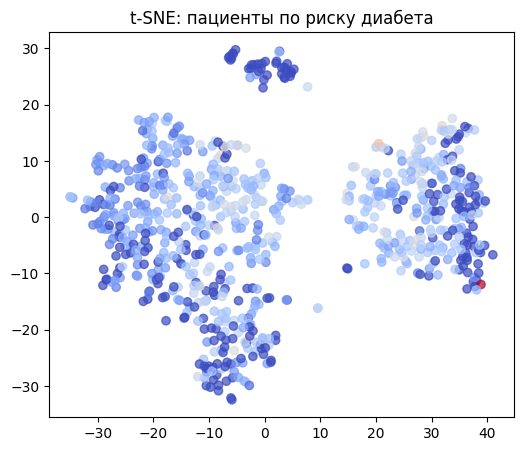

In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# понижение размерности и визуализация данных

data = pd.read_csv("diabetes.csv")
X = data.drop("SkinThickness", axis=1)
y = data["SkinThickness"]

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(6,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap="coolwarm", alpha=0.7)
plt.title("PCA: пациенты по риску диабета")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(6,5))
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=y, cmap="coolwarm", alpha=0.7)
plt.title("t-SNE: пациенты по риску диабета")
plt.show()


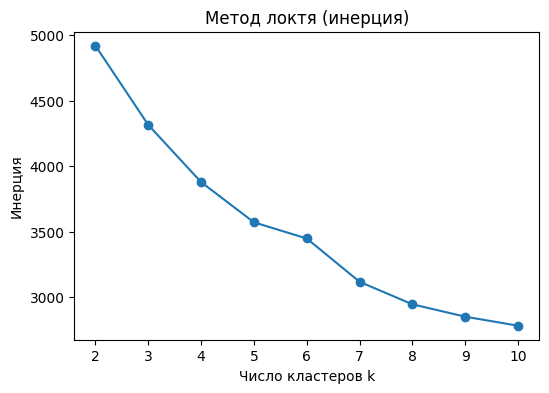

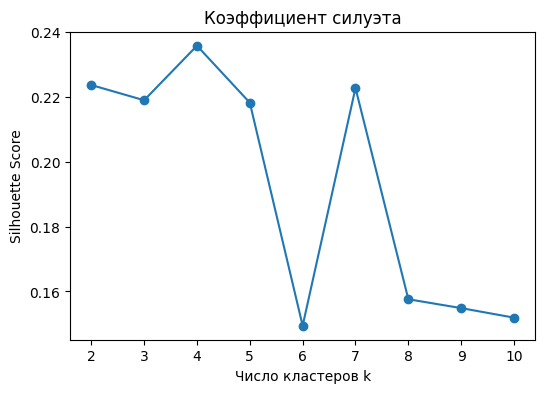

In [3]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Загрузка данных
data = pd.read_csv("diabetes.csv")
X = data.drop("SkinThickness", axis=1)

# Нормализация
X_scaled = StandardScaler().fit_transform(X)

inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(6,4))
plt.plot(K, inertia, marker='o')
plt.title("Метод локтя (инерция)")
plt.xlabel("Число кластеров k")
plt.ylabel("Инерция")
plt.show()

plt.figure(figsize=(6,4))
plt.plot(K, silhouette, marker='o')
plt.title("Коэффициент силуэта")
plt.xlabel("Число кластеров k")
plt.ylabel("Silhouette Score")
plt.show()


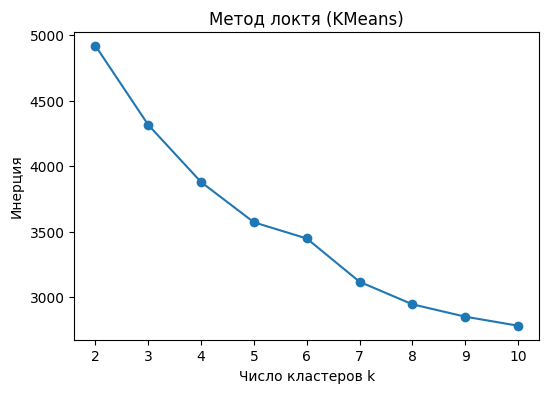

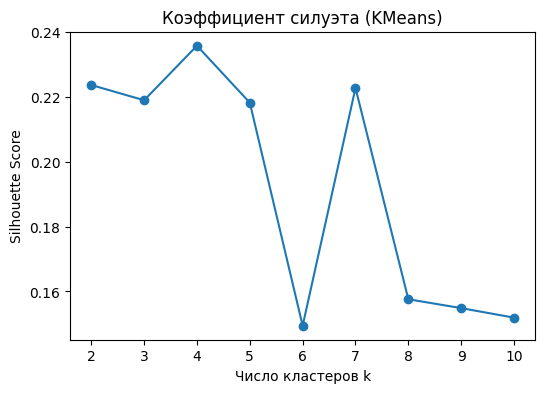

Silhouette Score (Agglomerative, k=3): 0.1595942439317077


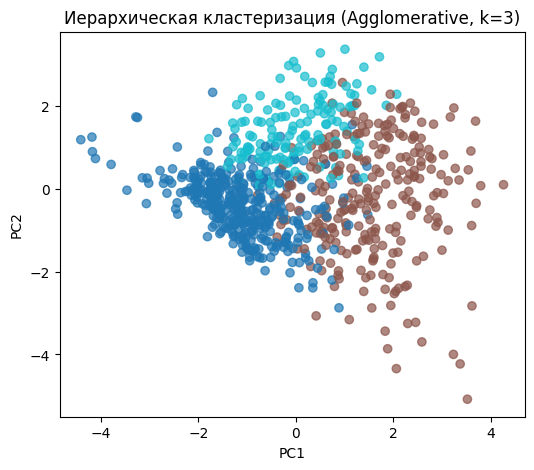

In [4]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Загрузка данных
data = pd.read_csv("diabetes.csv")
X = data.drop("SkinThickness", axis=1)

# Нормализация
X_scaled = StandardScaler().fit_transform(X)

# -----------------------------
# 1. Неиерархическая кластеризация (KMeans)
# -----------------------------
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

# График инерции (метод локтя)
plt.figure(figsize=(6,4))
plt.plot(K, inertia, marker='o')
plt.title("Метод локтя (KMeans)")
plt.xlabel("Число кластеров k")
plt.ylabel("Инерция")
plt.show()

# График силуэта
plt.figure(figsize=(6,4))
plt.plot(K, silhouette, marker='o')
plt.title("Коэффициент силуэта (KMeans)")
plt.xlabel("Число кластеров k")
plt.ylabel("Silhouette Score")
plt.show()

# -----------------------------
# 2. Иерархическая кластеризация (Agglomerative Clustering)
# -----------------------------
# Выберем оптимальное число кластеров, например k=3
agglo = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_agglo = agglo.fit_predict(X_scaled)

# Оценка силуэта
silhouette_agglo = silhouette_score(X_scaled, labels_agglo)
print("Silhouette Score (Agglomerative, k=3):", silhouette_agglo)

# Визуализация результатов (PCA для снижения размерности)
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(6,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_agglo, cmap="tab10", alpha=0.7)
plt.title("Иерархическая кластеризация (Agglomerative, k=3)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


In [5]:
from sklearn.metrics import silhouette_score

# KMeans (например, для k=3)
kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)
sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
print("Silhouette Score (KMeans, k=3):", sil_kmeans)

# Agglomerative Clustering (например, для k=3)
agglo = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_agglo = agglo.fit_predict(X_scaled)
sil_agglo = silhouette_score(X_scaled, labels_agglo)
print("Silhouette Score (Agglomerative, k=3):", sil_agglo)


Silhouette Score (KMeans, k=3): 0.23584073487797194
Silhouette Score (Agglomerative, k=3): 0.18132733646058763


Первые 5 строк датасета:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Размер датасета: (768, 9)

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancie

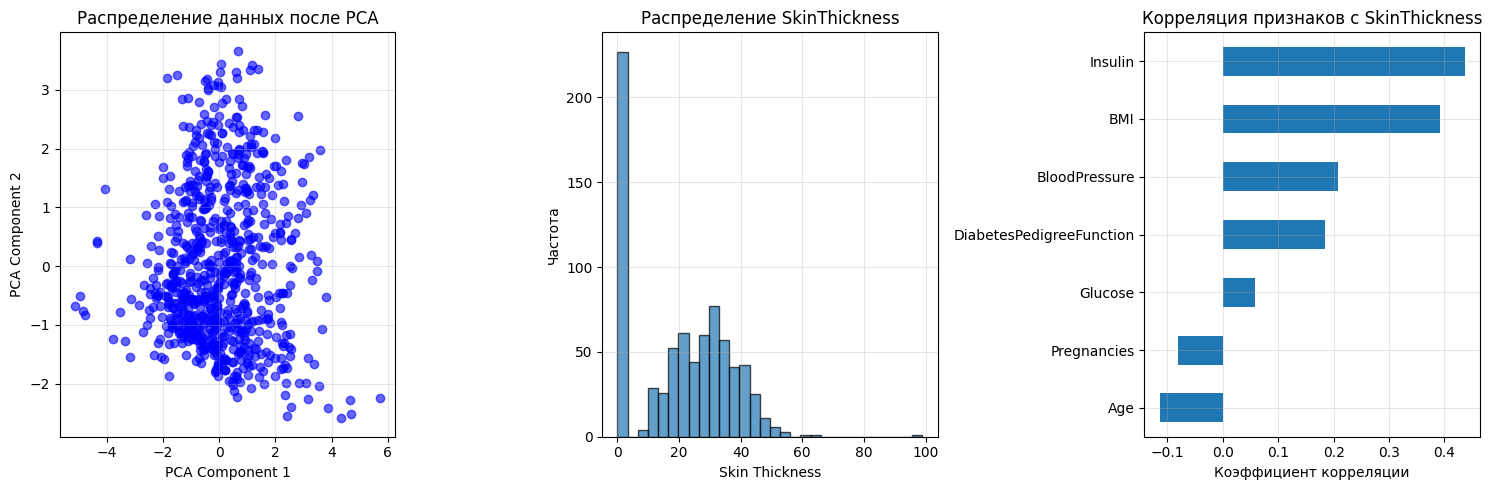


3. ВЫБОР КОЛИЧЕСТВА КЛАСТЕРОВ
Кластеров: 2, Инерция: 5128.81, Силуэт: 0.196
Кластеров: 3, Инерция: 4359.94, Силуэт: 0.180
Кластеров: 4, Инерция: 3920.60, Силуэт: 0.195
Кластеров: 5, Инерция: 3625.74, Силуэт: 0.188
Кластеров: 6, Инерция: 3386.92, Силуэт: 0.165
Кластеров: 7, Инерция: 3138.65, Силуэт: 0.169
Кластеров: 8, Инерция: 2999.02, Силуэт: 0.168
Кластеров: 9, Инерция: 2872.35, Силуэт: 0.171
Кластеров: 10, Инерция: 2765.21, Силуэт: 0.161


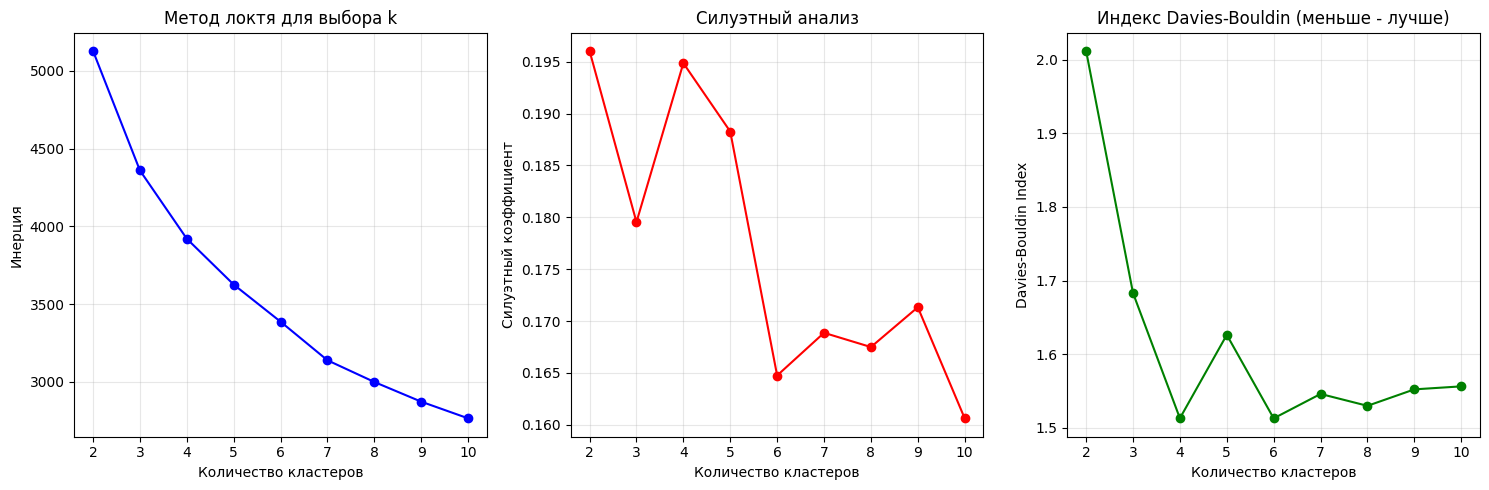


Оптимальное количество кластеров:
- По методу локтя: 4
- По силуэтному коэффициенту: 2
- По Davies-Bouldin Index: 6

Выбранное количество кластеров: 4

4. КЛАСТЕРНЫЙ АНАЛИЗ

4.1. K-MEANS КЛАСТЕРИЗАЦИЯ

4.2. ИЕРАРХИЧЕСКАЯ КЛАСТЕРИЗАЦИЯ


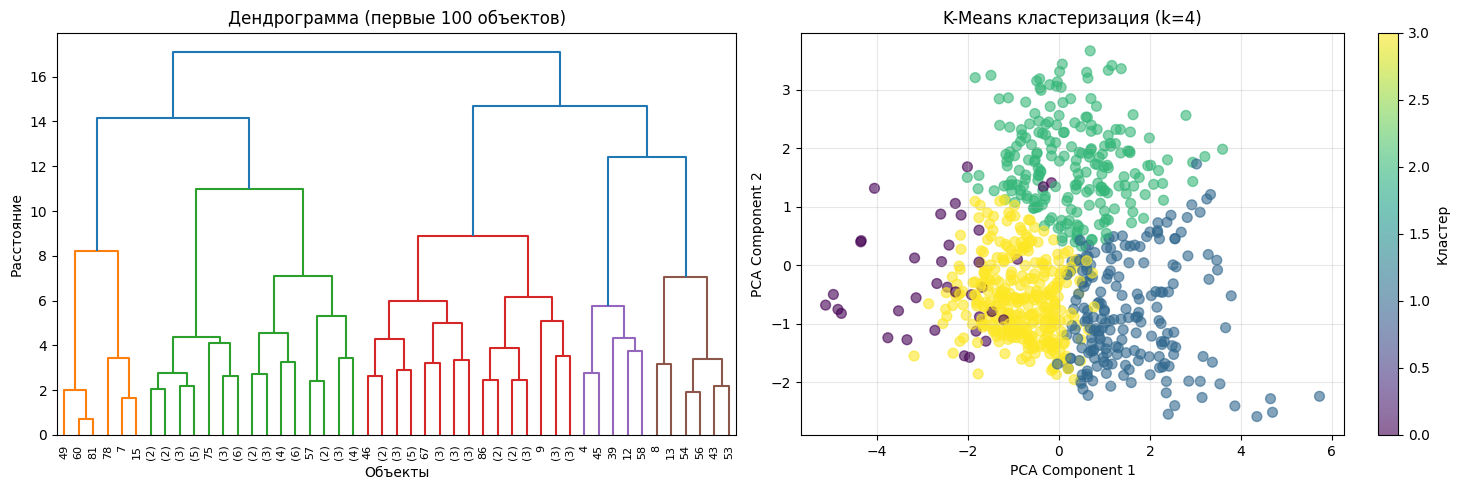


5. ОЦЕНКА КАЧЕСТВА КЛАСТЕРИЗАЦИИ

K-Means:
- Силуэтный коэффициент: 0.195
- Davies-Bouldin Index: 1.513 (меньше - лучше)
- Calinski-Harabasz Index: 144.42 (больше - лучше)

Иерархическая кластеризация:
- Силуэтный коэффициент: 0.169
- Davies-Bouldin Index: 1.836 (меньше - лучше)
- Calinski-Harabasz Index: 105.92 (больше - лучше)

АНАЛИЗ КЛАСТЕРОВ K-MEANS

Средние значения по кластерам (K-Means):
                Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  \
Cluster_KMeans                                                                
0                      3.56   117.00           0.67           2.00     0.69   
1                      2.78   142.52          73.27          34.96   204.58   
2                      7.44   130.03          78.28          13.97    34.49   
3                      2.17   102.39          68.20          18.22    43.25   

                  BMI  DiabetesPedigreeFunction    Age  Outcome  
Cluster_KMeans                                             

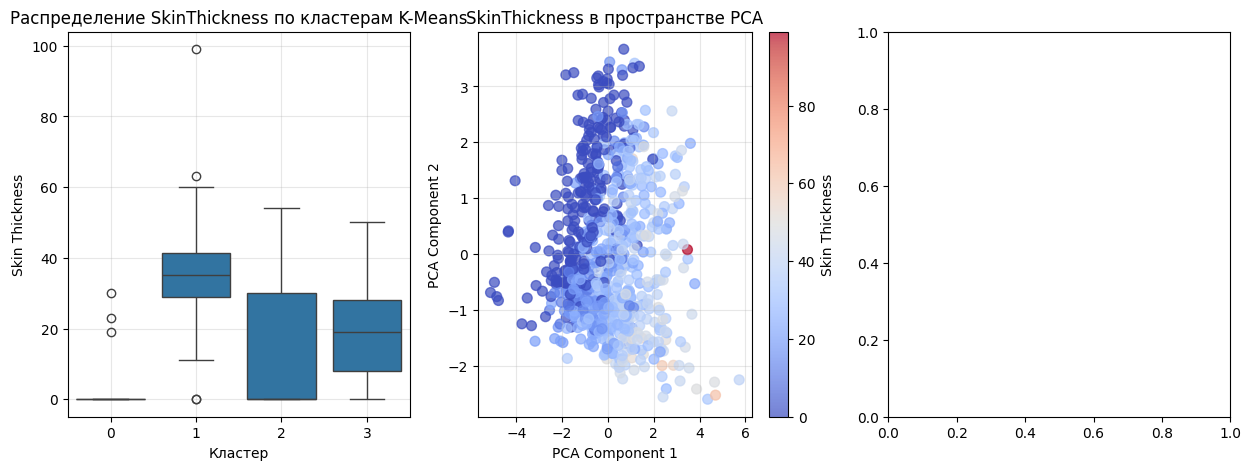

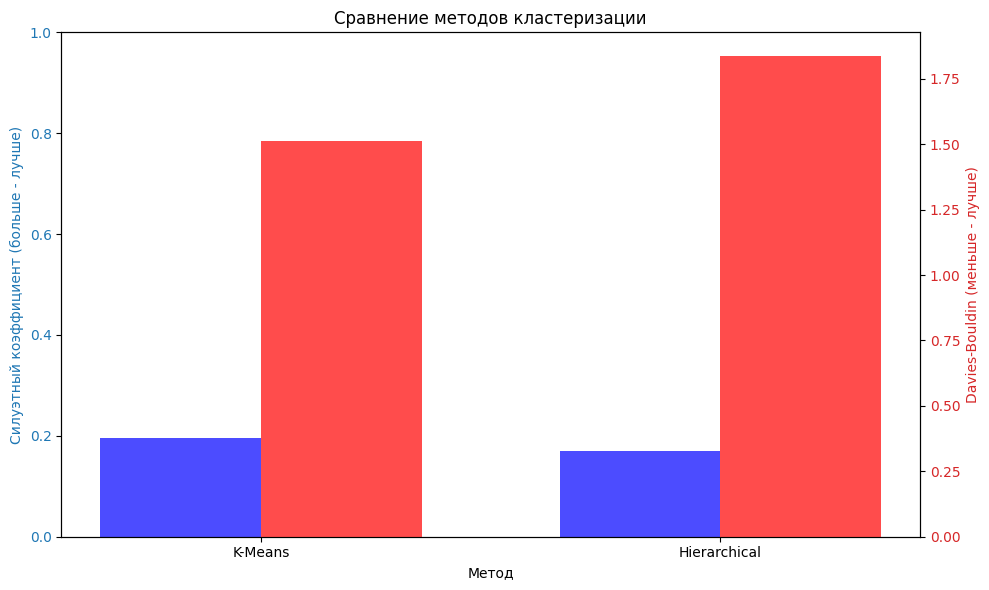


ВЫВОДЫ И РЕКОМЕНДАЦИИ

1. Оптимальное количество кластеров: 4 групп пациентов выделено на основе анализа
2. K-Means показал 0.19486375276167686 силуэтный коэффициент, иерархическая кластеризация - 0.16948676498930018
3. Кластеры различаются по средним значениям SkinThickness:

Кластер 0:
  • Размер: 36 пациентов (4.7%)
  • Средняя толщина кожи: 2.0 ± 6.9
  • Диапазон: 0-30
  • Тип: Низкая толщина кожи

Кластер 1:
  • Размер: 195 пациентов (25.4%)
  • Средняя толщина кожи: 35.0 ± 11.0
  • Диапазон: 0-99
  • Тип: Высокая толщина кожи

Кластер 2:
  • Размер: 212 пациентов (27.6%)
  • Средняя толщина кожи: 14.0 ± 15.9
  • Диапазон: 0-54
  • Тип: Низкая толщина кожи

Кластер 3:
  • Размер: 325 пациентов (42.3%)
  • Средняя толщина кожи: 18.2 ± 12.8
  • Диапазон: 0-50
  • Тип: Низкая толщина кожи


ПРАКТИЧЕСКИЕ РЕКОМЕНДАЦИИ:
1. Для кластеров с низкой толщиной кожи - рекомендации по питанию и уходу
2. Для кластеров с высокой толщиной кожи - дополнительный мониторинг связанных показателей
3. 

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Загрузка данных
# Предполагаем, что данные в файле diabetes.csv
df = pd.read_csv('diabetes.csv')

print("Первые 5 строк датасета:")
print(df.head())
print(f"\nРазмер датасета: {df.shape}")
print(f"\nИнформация о данных:")
print(df.info())
print(f"\nСтатистика по данным:")
print(df.describe())

# ============================================
# 1. БИЗНЕС-ЦЕЛЬ
# ============================================
print("\n" + "="*50)
print("1. БИЗНЕС-ЦЕЛЬ")
print("="*50)
print("""
Набор данных содержит медицинские показатели пациентов с диабетом.
Цель: Выявить группы пациентов с различными характеристиками толщины кожи (SkinThickness)
для персонализированных подходов в лечении и наблюдении.

Конкретные бизнес-цели:
1. Сегментация пациентов по физиологическим особенностям
2. Выявление пациентов с аномальными значениями толщины кожи
3. Разработка таргетированных рекомендаций для каждой группы
""")

# ============================================
# 2. ПОДГОТОВКА ДАННЫХ И ПОНИЖЕНИЕ РАЗМЕРНОСТИ
# ============================================
print("\n" + "="*50)
print("2. ПОДГОТОВКА ДАННЫХ И ПОНИЖЕНИЕ РАЗМЕРНОСТИ")
print("="*50)

# Копируем датасет для работы
data = df.copy()

# Проверка на пропущенные значения
print(f"Пропущенные значения:\n{data.isnull().sum()}")

# Выделяем фичи для кластеризации
# Включаем SkinThickness как основную переменную и другие релевантные признаки
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
            'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = data[features]

# Стандартизация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Понижение размерности с помощью PCA для визуализации
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"\nОбъясненная дисперсия PCA: {pca.explained_variance_ratio_}")
print(f"Суммарная объясненная дисперсия: {sum(pca.explained_variance_ratio_):.2%}")

# Визуализация данных после PCA
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, c='blue')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Распределение данных после PCA')
plt.grid(True, alpha=0.3)

# Гистограмма SkinThickness
plt.subplot(1, 3, 2)
plt.hist(data['SkinThickness'], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Skin Thickness')
plt.ylabel('Частота')
plt.title('Распределение SkinThickness')
plt.grid(True, alpha=0.3)

# Анализ корреляций с SkinThickness
plt.subplot(1, 3, 3)
correlations = data[features].corr()['SkinThickness'].drop('SkinThickness')
correlations.sort_values().plot(kind='barh')
plt.xlabel('Коэффициент корреляции')
plt.title('Корреляция признаков с SkinThickness')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================
# 3. ВЫБОР КОЛИЧЕСТВА КЛАСТЕРОВ
# ============================================
print("\n" + "="*50)
print("3. ВЫБОР КОЛИЧЕСТВА КЛАСТЕРОВ")
print("="*50)

# Метод локтя (inertia) и силуэтный анализ
inertia = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    
    # Силуэтный коэффициент
    silhouette_avg = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(silhouette_avg)
    print(f"Кластеров: {k}, Инерция: {kmeans.inertia_:.2f}, Силуэт: {silhouette_avg:.3f}")

# Визуализация методов выбора количества кластеров
plt.figure(figsize=(15, 5))

# Метод локтя
plt.subplot(1, 3, 1)
plt.plot(k_range, inertia, 'bo-')
plt.xlabel('Количество кластеров')
plt.ylabel('Инерция')
plt.title('Метод локтя для выбора k')
plt.grid(True, alpha=0.3)

# Силуэтный анализ
plt.subplot(1, 3, 2)
plt.plot(k_range, silhouette_scores, 'ro-')
plt.xlabel('Количество кластеров')
plt.ylabel('Силуэтный коэффициент')
plt.title('Силуэтный анализ')
plt.grid(True, alpha=0.3)

# Davies-Bouldin Index
davies_scores = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    davies_scores.append(davies_bouldin_score(X_scaled, labels))

plt.subplot(1, 3, 3)
plt.plot(k_range, davies_scores, 'go-')
plt.xlabel('Количество кластеров')
plt.ylabel('Davies-Bouldin Index')
plt.title('Индекс Davies-Bouldin (меньше - лучше)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Выбор оптимального количества кластеров
optimal_k_elbow = 4  # Определяется по графику "локтя"
optimal_k_silhouette = k_range[np.argmax(silhouette_scores)]
optimal_k_davies = k_range[np.argmin(davies_scores)]

print(f"\nОптимальное количество кластеров:")
print(f"- По методу локтя: {optimal_k_elbow}")
print(f"- По силуэтному коэффициенту: {optimal_k_silhouette}")
print(f"- По Davies-Bouldin Index: {optimal_k_davies}")

# Используем среднее значение для устойчивости
optimal_k = int(np.round(np.mean([optimal_k_elbow, optimal_k_silhouette, optimal_k_davies])))
print(f"\nВыбранное количество кластеров: {optimal_k}")

# ============================================
# 4. КЛАСТЕРНЫЙ АНАЛИЗ
# ============================================
print("\n" + "="*50)
print("4. КЛАСТЕРНЫЙ АНАЛИЗ")
print("="*50)

# 4.1. Неиерархическая кластеризация (K-Means)
print("\n4.1. K-MEANS КЛАСТЕРИЗАЦИЯ")
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# 4.2. Иерархическая кластеризация
print("\n4.2. ИЕРАРХИЧЕСКАЯ КЛАСТЕРИЗАЦИЯ")
hierarchical = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Дендрограмма для иерархической кластеризации
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
linked = linkage(X_scaled[:100], 'ward')  # Берем подвыборку для наглядности
dendrogram(linked, orientation='top', truncate_mode='level', p=5)
plt.title('Дендрограмма (первые 100 объектов)')
plt.xlabel('Объекты')
plt.ylabel('Расстояние')

# Визуализация кластеров в пространстве PCA
plt.subplot(1, 2, 2)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, 
                     cmap='viridis', alpha=0.6, s=50)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title(f'K-Means кластеризация (k={optimal_k})')
plt.colorbar(scatter, label='Кластер')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================
# 5. АНАЛИЗ И ОЦЕНКА КАЧЕСТВА
# ============================================
print("\n" + "="*50)
print("5. ОЦЕНКА КАЧЕСТВА КЛАСТЕРИЗАЦИИ")
print("="*50)

# Функция для оценки качества
def evaluate_clustering(X, labels, algorithm_name):
    if len(np.unique(labels)) > 1:  # Нужно как минимум 2 кластера
        silhouette = silhouette_score(X, labels)
        davies = davies_bouldin_score(X, labels)
        calinski = calinski_harabasz_score(X, labels)
        
        print(f"\n{algorithm_name}:")
        print(f"- Силуэтный коэффициент: {silhouette:.3f}")
        print(f"- Davies-Bouldin Index: {davies:.3f} (меньше - лучше)")
        print(f"- Calinski-Harabasz Index: {calinski:.2f} (больше - лучше)")
        
        return silhouette, davies, calinski
    else:
        print(f"{algorithm_name}: Недостаточно кластеров для оценки")
        return 0, float('inf'), 0

# Оценка качества для каждого метода
kmeans_metrics = evaluate_clustering(X_scaled, kmeans_labels, "K-Means")
hierarchical_metrics = evaluate_clustering(X_scaled, hierarchical_labels, "Иерархическая кластеризация")

# Анализ характеристик кластеров (для K-Means)
data['Cluster_KMeans'] = kmeans_labels
data['Cluster_Hierarchical'] = hierarchical_labels

print("\n" + "="*50)
print("АНАЛИЗ КЛАСТЕРОВ K-MEANS")
print("="*50)

# Средние значения по кластерам для K-Means
cluster_stats_kmeans = data.groupby('Cluster_KMeans')[features + ['Outcome']].mean()
print("\nСредние значения по кластерам (K-Means):")
print(cluster_stats_kmeans.round(2))

# Размеры кластеров
print("\nРазмеры кластеров (K-Means):")
print(data['Cluster_KMeans'].value_counts().sort_index())

# Анализ распределения SkinThickness по кластерам
print("\n" + "="*50)
print("РАСПРЕДЕЛЕНИЕ SKINTHICKNESS ПО КЛАСТЕРАМ")
print("="*50)

plt.figure(figsize=(15, 5))

# Boxplot SkinThickness по кластерам K-Means
plt.subplot(1, 3, 1)
sns.boxplot(x='Cluster_KMeans', y='SkinThickness', data=data)
plt.title('Распределение SkinThickness по кластерам K-Means')
plt.xlabel('Кластер')
plt.ylabel('Skin Thickness')
plt.grid(True, alpha=0.3)

# Scatter plot с акцентом на SkinThickness
plt.subplot(1, 3, 2)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data['SkinThickness'], 
                     cmap='coolwarm', alpha=0.7, s=50)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('SkinThickness в пространстве PCA')
plt.colorbar(scatter, label='Skin Thickness')
plt.grid(True, alpha=0.3)

# Сравнение методов кластеризации
plt.subplot(1, 3, 3)
comparison_data = pd.DataFrame({
    'Method': ['K-Means'] * len(kmeans_labels) + ['Hierarchical'] * len(hierarchical_labels),
    'Silhouette': [kmeans_metrics[0]] * len(kmeans_labels) + [hierarchical_metrics[0]] * len(hierarchical_labels),
    'Cluster': list(kmeans_labels) + list(hierarchical_labels)
})

# Создаем искусственные данные для визуализации
methods = ['K-Means', 'Hierarchical']
silhouette_values = [kmeans_metrics[0], hierarchical_metrics[0]]
davies_values = [kmeans_metrics[1], hierarchical_metrics[1]]

x = np.arange(len(methods))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax1.set_xlabel('Метод')
ax1.set_ylabel('Силуэтный коэффициент (больше - лучше)', color=color)
bars1 = ax1.bar(x - width/2, silhouette_values, width, label='Силуэт', color='blue', alpha=0.7)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim([0, 1])

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Davies-Bouldin (меньше - лучше)', color=color)
bars2 = ax2.bar(x + width/2, davies_values, width, label='Davies-Bouldin', color='red', alpha=0.7)
ax2.tick_params(axis='y', labelcolor=color)

ax1.set_xticks(x)
ax1.set_xticklabels(methods)
ax1.set_title('Сравнение методов кластеризации')
fig.tight_layout()
plt.show()

# Вывод рекомендаций на основе анализа
print("\n" + "="*50)
print("ВЫВОДЫ И РЕКОМЕНДАЦИИ")
print("="*50)

print("""
1. Оптимальное количество кластеров: {} групп пациентов выделено на основе анализа
2. K-Means показал {} силуэтный коэффициент, иерархическая кластеризация - {}
3. Кластеры различаются по средним значениям SkinThickness:
""".format(optimal_k, kmeans_metrics[0], hierarchical_metrics[0]))

# Анализ каждого кластера по SkinThickness
for cluster in sorted(data['Cluster_KMeans'].unique()):
    cluster_data = data[data['Cluster_KMeans'] == cluster]
    avg_skin = cluster_data['SkinThickness'].mean()
    std_skin = cluster_data['SkinThickness'].std()
    size = len(cluster_data)
    
    print(f"Кластер {cluster}:")
    print(f"  • Размер: {size} пациентов ({size/len(data)*100:.1f}%)")
    print(f"  • Средняя толщина кожи: {avg_skin:.1f} ± {std_skin:.1f}")
    print(f"  • Диапазон: {cluster_data['SkinThickness'].min():.0f}-{cluster_data['SkinThickness'].max():.0f}")
    
    # Определение типа кластера по SkinThickness
    if avg_skin < 20:
        skin_type = "Низкая толщина кожи"
    elif avg_skin < 30:
        skin_type = "Средняя толщина кожи"
    else:
        skin_type = "Высокая толщина кожи"
    
    print(f"  • Тип: {skin_type}")
    print()

print("""
ПРАКТИЧЕСКИЕ РЕКОМЕНДАЦИИ:
1. Для кластеров с низкой толщиной кожи - рекомендации по питанию и уходу
2. Для кластеров с высокой толщиной кожи - дополнительный мониторинг связанных показателей
3. Разработка персонализированных планов наблюдения для каждого кластера
""")

# Сохранение результатов
data.to_csv('clustered_diabetes.csv', index=False)
print("\nРезультаты кластеризации сохранены в файл 'clustered_diabetes.csv'")